# SV vs SNP peaks — GEA (raw LFMM), climate PC1

**Miami plot:** SVs point up, SNPs point down, on one genome axis (chromosomes separated by gaps).
Dashed lines = each class's own Bonferroni (0.05 / n records of that class).

**Open red circles = new SV peaks**: a significant SV peak with **no significant SNP within
10 kb**. A peak = significant LD blocks (lead variant over the bar) merged when their variants
lie within 10 kb of each other.

SNPs with p > 0.01 (−log10 p < 2) are not drawn: ~2 M points far below any threshold that only add
file weight. SVs are drawn in full.

Then the three-way Venn of SV / SNP / non-SNP peaks on the same axis and the same peak rule.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
def _tree_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.basename(d) == "grenenet_selection" and os.path.exists(os.path.join(d, "lib.py")):
            return d
        d = os.path.dirname(d)
    raise RuntimeError("no grenenet_selection root above " + os.getcwd())
GS = _tree_root()
sys.path.insert(0, GS); sys.path.insert(0, f"{GS}/blocks"); sys.path.insert(0, f"{GS}/genes/convergence")
import lib, blocks_tiling as bt, plot_theme as TH
TH.apply()
WZAIN = f"{GS}/r2_gea_nonsnp/phase1_replication/results/multiaxis/wza_in_clq09_tile"
PLOTS = f"{GS}/notebooks/plots"; os.makedirs(PLOTS, exist_ok=True)
GENES = lib.load_genes()
WINDOW = 10000
CLASSES = ["snp", "nonsnp", "sv"]

CHROM_LEN = {"Chr1": 30427671, "Chr2": 19698289, "Chr3": 23459830, "Chr4": 18585056, "Chr5": 26975502}
GAP = 3_500_000                           # empty genome space between chromosomes
CH = list(CHROM_LEN); OFF = {}; _a = 0
for _c in CH: OFF[_c] = _a; _a += CHROM_LEN[_c] + GAP
GENOME = _a - GAP

# tiling block spans: block i owns (end_{i-1}, end_i]
SPAN = {}
for ch in CH:
    ends = bt.load_blocks(0.9, ch).end_pos.to_numpy(np.int64)
    for i, e in enumerate(ends):
        SPAN[f"{ch}_{i}"] = (ch, 1 if i == 0 else int(ends[i - 1]) + 1, int(e))

BG = {"snp": ("#B4B4B4", "#D2D2D2"), "nonsnp": ("#AFCDAF", "#D2E4D2"), "sv": ("#A3C2A8", "#CCDDCF")}
LAB = {"snp": "SNP", "nonsnp": "non-SNP", "sv": "SV"}
SHARED, NEW, SNPONLY = TH.COLD, TH.ACCENT, "#4A4A4A"
BIONAME = {"bio1": "annual mean temperature", "bio10": "mean temperature of warmest quarter",
           "bio15": "precipitation seasonality", "pc1": "climate PC1", "pc3": "climate PC3"}

def load(cls, axis):
    d = pd.read_csv(f"{WZAIN}/lfmm_{cls}_gen9_{axis}.csv", usecols=["chrom", "pos", "MAF", "pval"])
    d = d[d.MAF > 0.05].copy()
    d["block"] = bt.assign_tiling(d.chrom.to_numpy(), d.pos.to_numpy(), r2=0.9)
    d["nlp"] = -np.log10(d.pval.clip(lower=1e-300))
    d["x"] = d.chrom.map(OFF) + d.pos
    d.attrs["bar"] = -np.log10(0.05 / len(d))
    return d

def sig_blocks(d):
    lead = d.groupby("block").nlp.max()
    return set(lead.index[lead > d.attrs["bar"]])

def make_loci(D, window):
    # merge the significant blocks of every class into loci: spans within `window` bp join
    # a block's extent here is the span of that class's own records in it, NOT the tiling span:
    # tiling blocks absorb inter-block gaps (up to Mb across a centromere), which chained
    # variants a megabase apart into one "peak"
    rows = []
    for cls in CLASSES:
        d = D[cls]; sb = sig_blocks(d)
        ext = d[d.block.isin(sb)].groupby("block").agg(chrom=("chrom", "first"), start=("pos", "min"),
                                                       end=("pos", "max")).reset_index()
        ext["cls"] = cls
        rows.append(ext)
    t = pd.concat(rows)[["block", "cls", "chrom", "start", "end"]].sort_values(["chrom", "start"])
    lid, cur, pch, pend = [], -1, None, -np.inf
    for r in t.itertuples():
        if r.chrom != pch or r.start - pend > window:
            cur += 1; pend = r.end
        else:
            pend = max(pend, r.end)
        pch = r.chrom; lid.append(cur)
    t["locus"] = lid
    L = t.groupby("locus").agg(chrom=("chrom", "first"), start=("start", "min"), end=("end", "max"),
                               classes=("cls", lambda s: set(s)))
    return L

def locus_table(D, L):
    # per locus x class: lead record inside the locus span (sig classes only) + SNP margin + status
    out = []
    for lid, r in L.iterrows():
        snp_in = D["snp"][(D["snp"].chrom == r.chrom) & D["snp"].pos.between(r.start, r.end)]
        snp_margin = (snp_in.nlp.max() - D["snp"].attrs["bar"]) if len(snp_in) else -np.inf
        for cls in r.classes:
            d = D[cls]; q = d[(d.chrom == r.chrom) & d.pos.between(r.start, r.end)]
            best = q.loc[q.nlp.idxmax()]
            if cls == "snp":
                st = "shared" if len(r.classes) > 1 else "snp_only"
            elif "snp" in r.classes:
                st = "shared"
            else:
                st = "new_near_miss" if snp_margin > -2 else "new_snp_blind"
            out.append(dict(locus=lid, cls=cls, chrom=r.chrom, pos=int(best.pos), x=int(best.x),
                            nlp=float(best.nlp), status=st, width_kb=(r.end - r.start) / 1e3))
    return pd.DataFrame(out)

def gene_at(chrom, pos):
    g = GENES[GENES.chrom == chrom]
    inside = g[(g.start <= pos) & (g.end >= pos)]
    if len(inside): return inside.gene.iloc[0]
    dist = np.minimum((g.start - pos).abs(), (g.end - pos).abs())
    return g.gene.iloc[int(np.argmin(dist.to_numpy()))] + "*"     # * = nearest, not inside

print(f"{len(GENES):,} genes, {len(SPAN):,} tiling blocks; locus window {WINDOW // 1000} kb")

27,206 genes, 58,376 tiling blocks; locus window 10 kb


In [2]:
def track(ax, d, cls, down, lo, hi, s):
    k = d[(d.x >= lo) & (d.x <= hi)]
    for i, ch in enumerate(CH):
        kc = k[k.chrom == ch]
        if len(kc):
            ax.scatter(kc.x, kc.nlp, s=s, c=BG[cls][i % 2], linewidths=0, rasterized=True, zorder=1)
    ax.axhline(d.attrs["bar"], ls="--", lw=0.8, color=TH.MUTED, zorder=2)
    ax.set_ylim(0, max(k.nlp.max(), d.attrs["bar"]) * 1.12)      # headroom: nothing clipped
    if down: ax.invert_yaxis()
    ax.set_ylabel(f"{LAB[cls]}\n−log10 p", labelpad=8)
    TH.grid_only(ax, "y")

def mark(ax, q, size):
    for st, kw in [("shared", dict(color=SHARED, edgecolor="white", linewidth=0.7, zorder=5)),
                   ("snp_only", dict(color=SNPONLY, edgecolor="white", linewidth=0.5, zorder=4)),
                   ("new_near_miss", dict(facecolor="white", edgecolor=NEW, linewidth=1.4, zorder=5)),
                   ("new_snp_blind", dict(color=NEW, edgecolor="white", linewidth=0.7, zorder=6))]:
        z = q[q.status == st]
        ax.scatter(z.x, z.nlp, s=size * (0.6 if st == "snp_only" else 1), **kw)

def legend(fig):
    h = [Line2D([], [], marker="o", ls="", color=SHARED, markersize=8, label="shared peak (SNP + this class)"),
         Line2D([], [], marker="o", ls="", color=NEW, markersize=8, label="new peak · SNP-blind"),
         Line2D([], [], marker="o", ls="", markerfacecolor="white", markeredgecolor=NEW,
                markeredgewidth=1.4, markersize=8, label="new peak · SNP near-miss"),
         Line2D([], [], marker="o", ls="", color=SNPONLY, markersize=6, label="SNP-only peak"),
         Line2D([], [], ls="--", color=TH.MUTED, label="Bonferroni (per class)")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=5, fontsize=9.5)

ORDER = ["sv", "snp", "nonsnp"]           # SVs are the subject: first track, pointing up
DOWN = {"sv": False, "snp": True, "nonsnp": True}

def panel(axis, D, T, lo, hi, chrom=None, labels=0, dot=1.0, s_bg=1.6, fname=None):
    fig, axs = plt.subplots(3, 1, figsize=(17, 8.6), sharex=True,
                            gridspec_kw=dict(height_ratios=[0.9, 1.1, 1], hspace=0.08))
    for ax, cls in zip(axs, ORDER):
        track(ax, D[cls], cls, DOWN[cls], lo, hi, s_bg)
    T = T[(T.x >= lo) & (T.x <= hi)]
    axs[-1].set_xlim(lo, hi)
    for ax, cls in zip(axs, ORDER):
        mark(ax, T[T.cls == cls], 34 * dot)
    for ax, cls in zip(axs, ORDER):
        q = T[T.cls == cls]; n = q.status.value_counts()
        if cls == "snp":
            txt = f"{len(q)} SNP peaks · {n.get('shared', 0)} shared with SV or non-SNP"
        else:
            txt = (f"{len(q)} {LAB[cls]} peaks · {n.get('shared', 0)} shared with SNP · "
                   f"{n.get('new_snp_blind', 0)} new SNP-blind · {n.get('new_near_miss', 0)} new near-miss")
        TH.note(ax, txt, x=0.005, y=0.86 if not DOWN[cls] else 0.06, color=TH.TICK)
        if labels and cls != "snp":
            top = q[q.status == "new_snp_blind"].nlargest(labels, "nlp").sort_values("x")
            last_x, k = -np.inf, 0
            sgn = 1 if DOWN[cls] else -1          # stagger away from the data floor
            for _, r in top.iterrows():
                k = k + 1 if r.x - last_x < 0.07 * (hi - lo) else 0
                last_x = r.x
                ax.annotate(gene_at(r.chrom, r.pos), (r.x, r.nlp), xytext=(6, -11 * k * sgn),
                            textcoords="offset points", fontsize=8, color=NEW, ha="left", va="center",
                            arrowprops=dict(arrowstyle="-", color=NEW, lw=0.5) if k else None)
    TH.note(axs[0], f"{axis} · {BIONAME.get(axis, '')}" + (f" · {chrom}" if chrom else "") +
            f" · peaks = significant blocks merged within {WINDOW // 1000} kb",
            x=0.005, y=0.98, color=TH.TICK)
    for ax in axs[:-1]:
        ax.tick_params(axis="x", length=0)          # no tick marks between the panels
    if chrom is None:
        axs[-1].set_xticks([OFF[c] + CHROM_LEN[c] / 2 for c in CH]); axs[-1].set_xticklabels(CH, fontsize=11)
        axs[-1].tick_params(axis="x", length=0)
    else:
        mb = np.arange(0, CHROM_LEN[chrom] / 1e6, 2.5)
        axs[-1].set_xticks(OFF[chrom] + mb * 1e6); axs[-1].set_xticklabels([f"{m:g}" for m in mb])
        axs[-1].set_xlabel(f"{chrom} position (Mb)")
    legend(fig)
    if fname:
        for ext in ["png", "pdf"]:
            plt.savefig(f"{PLOTS}/{fname.rsplit('.', 1)[0]}.{ext}", dpi=200, bbox_inches="tight", pad_inches=0.25)
    plt.show()

def venn_peaks(axis, T, fname=None):
    from matplotlib_venn import venn3
    S = {c: set(T.loc[T.cls == c, "locus"]) for c in ORDER}
    fig, ax = plt.subplots(figsize=(7, 6.3))
    v = venn3([S["sv"], S["snp"], S["nonsnp"]], set_labels=("SV", "SNP", "non-SNP"), ax=ax)
    col = {"100": "#1B5E20", "010": "#A6A6A6", "001": "#3F9B49"}
    for pid in ["100", "010", "001", "110", "101", "011", "111"]:
        p = v.get_patch_by_id(pid)
        if p is None: continue
        p.set_color(col.get(pid, "#6E8B74")); p.set_alpha(0.6 if pid in col else 0.55 + 0.1 * pid.count("1"))
        p.set_edgecolor("white"); p.set_linewidth(1.5)
    for t in v.set_labels:
        if t: t.set_fontsize(11); t.set_color(TH.LABEL)
    anyp = S["sv"] | S["snp"] | S["nonsnp"]
    lines = [f"{LAB[c]}: {len(S[c])} peaks" for c in ORDER]
    lines.append(f"{axis} · {len(anyp)} peaks in any class · peaks = significant blocks merged within "
                 f"{WINDOW // 1000} kb")
    lines.append(f"not SNP-significant: SV {len(S['sv'] - S['snp'])} · non-SNP {len(S['nonsnp'] - S['snp'])}")
    ax.annotate("\n".join(lines), (0.5, -0.02), xycoords="axes fraction", ha="center", va="top",
                fontsize=8.5, color=TH.TICK, linespacing=1.5)
    if fname:
        for ext in ["png", "pdf"]:
            plt.savefig(f"{PLOTS}/{fname.rsplit('.', 1)[0]}.{ext}", dpi=200, bbox_inches="tight", pad_inches=0.25)
    plt.show()

def run(axis, zoom_chrom=None):
    D = {c: load(c, axis) for c in CLASSES}
    # how much "new" depends on the merge window
    rows = []
    for w in [0, 10_000, 25_000, 50_000]:
        t = locus_table(D, make_loci(D, w))
        for cls in ["nonsnp", "sv"]:
            q = t[t.cls == cls]
            rows.append(dict(window_kb=w // 1000, cls=cls, peaks=len(q), shared=(q.status == "shared").sum(),
                             new=q.status.str.startswith("new").sum(),
                             new_snp_blind=(q.status == "new_snp_blind").sum()))
    display(pd.DataFrame(rows).pivot(index="window_kb", columns="cls"))
    T = locus_table(D, make_loci(D, WINDOW))
    panel(axis, D, T, 0, GENOME, fname=f"peak_alignment_gea_{axis}.png")
    if zoom_chrom is None:
        zoom_chrom = T[T.status == "new_snp_blind"].chrom.value_counts().idxmax()
    lo, hi = OFF[zoom_chrom], OFF[zoom_chrom] + CHROM_LEN[zoom_chrom]
    panel(axis, D, T, lo, hi, chrom=zoom_chrom, labels=8, dot=1.2, s_bg=3,
          fname=f"peak_alignment_gea_{axis}_{zoom_chrom}.png")
    venn_peaks(axis, T, fname=f"peak_venn_gea_{axis}.png")
    return D, T

In [3]:
from matplotlib.lines import Line2D
SVCOL, SVLIGHT = ("#3F7D4A", "#8DB896")
SNPCOL = ("#8A8A8A", "#C4C4C4")
SNP_FLOOR = 2.0                      # SNPs with -log10 p below this are not drawn

def sv_snp_peaks(D, bars, window):
    # SV and SNP significant blocks (lead > bar), record-span extents, merged within `window`
    rows = []
    for cls in ["sv", "snp"]:
        d = D[cls]; lead = d.groupby("block").nlp.max(); sb = set(lead.index[lead > bars[cls]])
        e = d[d.block.isin(sb)].groupby("block").agg(chrom=("chrom", "first"), start=("pos", "min"),
                                                     end=("pos", "max")).reset_index()
        e["cls"] = cls; rows.append(e)
    t = pd.concat(rows).sort_values(["chrom", "start"])
    lid, cur, pch, pend = [], -1, None, -np.inf
    for r in t.itertuples():
        if r.chrom != pch or r.start - pend > window: cur += 1; pend = r.end
        else: pend = max(pend, r.end)
        pch = r.chrom; lid.append(cur)
    t["locus"] = lid
    out = []
    for lid, g in t.groupby("locus"):
        ch, lo, hi = g.chrom.iloc[0], g.start.min(), g.end.max()
        cl = set(g.cls)
        if "sv" not in cl: continue
        q = D["sv"][(D["sv"].chrom == ch) & D["sv"].pos.between(lo, hi)]
        b = q.loc[q.nlp.idxmax()]
        out.append(dict(locus=lid, chrom=ch, pos=int(b.pos), x=int(b.x), nlp=float(b.nlp),
                        sv_only="snp" not in cl))
    return pd.DataFrame(out)

def manh(ax, d, cols, sign=1, s=1.6, marker="o"):
    for i, ch in enumerate(CH):
        k = d[d.chrom == ch]
        ax.scatter(k.x, sign * k.nlp, s=s, c=cols[i % 2], marker=marker, linewidths=0, rasterized=True, zorder=1)

def xaxis(ax):
    pad = 0.015 * GENOME                     # room for markers at the chromosome ends
    ax.set_xlim(-pad, GENOME + pad)
    ax.set_xticks([OFF[c] + CHROM_LEN[c] / 2 for c in CH]); ax.set_xticklabels(CH, fontsize=11)
    ax.tick_params(axis="x", length=0)

def tri(ax, P, sign=1, pad=0.5):
    q = P[P.sv_only]
    ax.scatter(q.x, sign * (q.nlp + pad), marker="v" if sign > 0 else "^", s=46, color=TH.ACCENT,
               edgecolor="white", linewidth=0.6, zorder=5)

def count_note(ax, P, window, thr, y=0.97):
    TH.note(ax, f"{len(P)} SV peaks · {P.sv_only.sum()} new (no significant SNP within "
                f"{window // 1000} kb) · {thr}", x=0.005, y=y, color=TH.TICK)

def ring(ax, P):
    # open circle drawn around the SV-only peak's lead point itself
    q = P[P.sv_only]
    ax.scatter(q.x, q.nlp, s=110, facecolor="none", edgecolor=TH.ACCENT, linewidth=1.5, alpha=0.75, zorder=5, clip_on=False)

def ring_legend(fig):
    h = [Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor=TH.ACCENT,
                markeredgewidth=1.5, markersize=10, alpha=0.75, label="new SV peak"),
         Line2D([], [], ls="--", color=TH.MUTED, label="Bonferroni")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=2, fontsize=9.5)

def tri_legend(fig, extra=()):
    h = [Line2D([], [], marker="v", ls="", color=TH.ACCENT, markersize=8, label="SV-only peak")]
    h += list(extra)
    h.append(Line2D([], [], ls="--", color=TH.MUTED, label="Bonferroni"))
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=len(h), fontsize=9.5)

def bars_for(D, shared):
    if not shared:
        return {c: D[c].attrs["bar"] for c in ["sv", "snp"]}, "per-class Bonferroni"
    b = -np.log10(0.05 / (len(D["sv"]) + len(D["snp"])))
    return {"sv": b, "snp": b}, "one shared Bonferroni 0.05/(n_SNP+n_SV)"

def option_stacked(tag, D, window, shared=False):
    bars, thr = bars_for(D, shared); P = sv_snp_peaks(D, bars, window)
    fig, axs = plt.subplots(2, 1, figsize=(17, 6.8), sharex=True, gridspec_kw=dict(hspace=0.12))
    for ax, cls, cols in zip(axs, ["sv", "snp"], [(SVCOL, SVLIGHT), SNPCOL]):
        manh(ax, D[cls], cols)
        ax.axhline(bars[cls], ls="--", lw=0.8, color=TH.MUTED)
        ax.set_ylabel(f"{LAB[cls]}\n−log10 p"); TH.grid_only(ax, "y")
        ax.set_ylim(0, max(D[cls].nlp.max(), bars[cls]) * 1.15)
    tri(axs[0], P)
    count_note(axs[0], P, window, thr)
    xaxis(axs[1]); axs[0].tick_params(axis="x", length=0)
    tri_legend(fig)
    plt.savefig(f"{PLOTS}/peak_option_{tag}.png", dpi=170, bbox_inches="tight", pad_inches=0.25); plt.show()
    return P

def option_miami(tag, D, window):
    bars, thr = bars_for(D, False); P = sv_snp_peaks(D, bars, window)
    fig, ax = plt.subplots(figsize=(17, 6.2))
    manh(ax, D["sv"], (SVCOL, SVLIGHT), +1)
    # SNPs below SNP_FLOOR are not drawn, and the SNP side is pulled up by SHIFT so the cut leaves
    # only a small gap under 0; SNP tick labels are the true -log10 p
    SHIFT = SNP_FLOOR - 0.5
    snp = D["snp"]; s = snp[snp.nlp >= SNP_FLOOR].copy(); s["nlp"] = s.nlp - SHIFT
    manh(ax, s, SNPCOL, -1)
    ax.axhline(bars["sv"], ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(-(bars["snp"] - SHIFT), ls="--", lw=0.8, color=TH.MUTED)
    ax.axhline(0, color=TH.AXIS, lw=0.8)
    ring(ax, P)
    top = D["sv"].nlp.max() * 1.12
    bot = (snp.nlp.max() - SHIFT) * 1.08
    ax.set_ylim(-bot, top)
    up = np.arange(0, top, 4); dn = np.arange(4, snp.nlp.max() + 1, 4)
    ax.set_yticks(np.r_[-(dn[::-1] - SHIFT), up])
    ax.set_yticklabels([f"{v:g}" for v in dn[::-1]] + [f"{v:g}" for v in up])
    ax.set_ylabel("−log10 p\nSNP ↓        SV ↑"); TH.grid_only(ax, "y")
    xaxis(ax); ring_legend(fig)
    for ext in ["png", "pdf"]:
        plt.savefig(f"{PLOTS}/peak_miami_gea_{tag.split('_')[0]}.{ext}", dpi=200, bbox_inches="tight", pad_inches=0.25)
    plt.show()
    print(f"{len(P)} SV peaks, {P.sv_only.sum()} new (no significant SNP within {window // 1000} kb; {thr}); "
          f"SNPs with p > 0.01 not drawn")
    return P

def option_overlay(tag, D, window):
    bars, thr = bars_for(D, False); P = sv_snp_peaks(D, bars, window)
    fig, ax = plt.subplots(figsize=(17, 5.4))
    manh(ax, D["snp"], ("#A9A9A9", "#D0D0D0"))
    sv = D["sv"]
    for i, ch in enumerate(CH):
        k = sv[sv.chrom == ch]
        ax.scatter(k.x, k.nlp, s=9, marker="^", c=(SVCOL, SVLIGHT)[i % 2], linewidths=0, rasterized=True, zorder=2)
    q = P[P.sv_only]
    ax.scatter(q.x, q.nlp, marker="^", s=70, color=TH.ACCENT, edgecolor="white", linewidth=0.7, zorder=5)
    ax.axhline(bars["snp"], ls="--", lw=0.8, color="#8A8A8A"); ax.axhline(bars["sv"], ls=":", lw=1.0, color=SVCOL)
    ax.set_ylim(0, max(sv.nlp.max(), D["snp"].nlp.max()) * 1.12)
    ax.set_ylabel("−log10 p"); TH.grid_only(ax, "y")
    count_note(ax, P, window, thr); xaxis(ax)
    h = [Line2D([], [], marker="o", ls="", color="#A9A9A9", markersize=5, label="SNP"),
         Line2D([], [], marker="^", ls="", color=SVCOL, markersize=6, label="SV"),
         Line2D([], [], marker="^", ls="", color=TH.ACCENT, markersize=9, label="SV-only peak"),
         Line2D([], [], ls="--", color="#8A8A8A", label="SNP Bonferroni"),
         Line2D([], [], ls=":", color=SVCOL, label="SV Bonferroni")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 0.9), ncol=5, fontsize=9.5)
    plt.savefig(f"{PLOTS}/peak_option_{tag}.png", dpi=170, bbox_inches="tight", pad_inches=0.25); plt.show()
    return P

## Miami plot — SV up, SNP down (pc1)

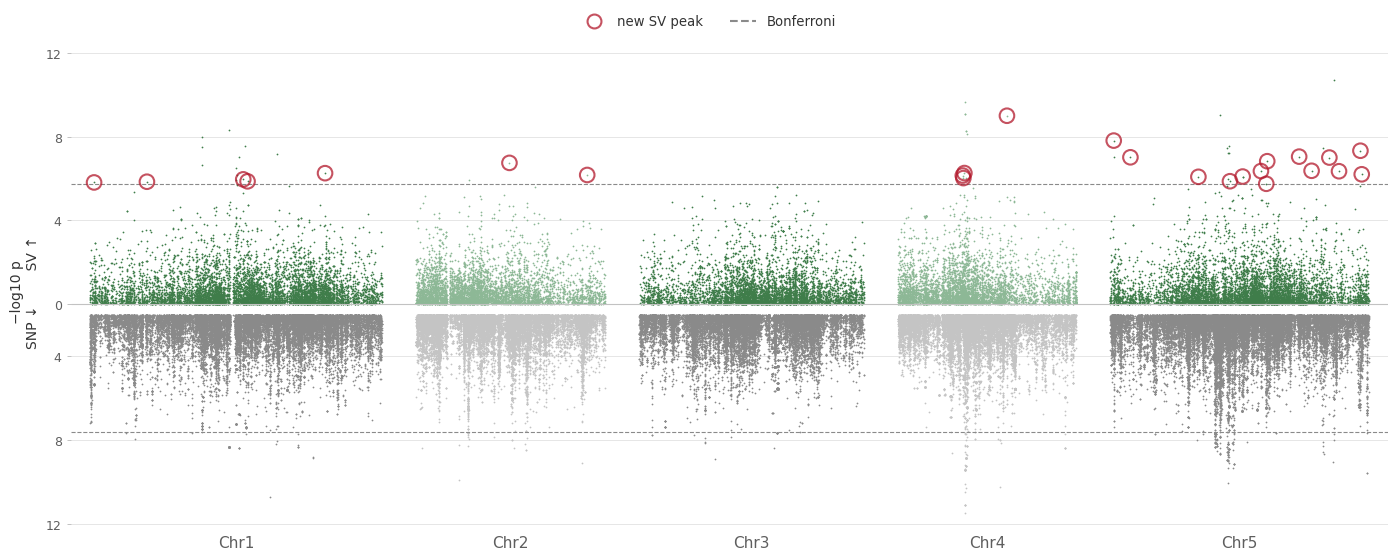

40 SV peaks, 25 new (no significant SNP within 10 kb; per-class Bonferroni); SNPs with p > 0.01 not drawn


In [4]:
D = {c: load(c, "pc1") for c in CLASSES}
P = option_miami("pc1_E", D, WINDOW)

## Venn — SV / SNP / non-SNP peaks (pc1)

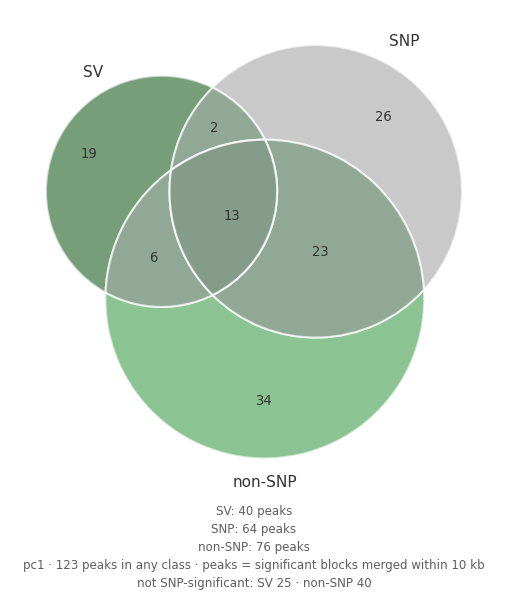

In [5]:
T = locus_table(D, make_loci(D, WINDOW))
venn_peaks("pc1", T, fname="peak_venn_gea_pc1.png")